# Threshold detection and ROC curves

Laboratory 6, DEDP

# 1. Objective

Simulate transmission of bits using two voltage levels with additive
noise, make receiver decisions by thresholding, and measure detections
and false alarms. Choose a maximum-likelihood threshold and plot an ROC
curve.

# 2. Theoretical aspects

## 2.1 Binary decisions by thresholding

A transmitter may represent each bit by a constant voltage level:

- bit 0: $s=0$ V; (or some other value)
- bit 1: $s=A$ V, where $A>0$.

The signal is corrupted by additive noise. The receiver takes one sample
per transmitted bit to make a decision. The received voltage is:

<span id="eq-received-voltage">$$
r=s+n,
 \qquad(1)$$</span>

where $n$ is additive noise. The two hypotheses describe what was
transmitted:

- $H_0$: bit 0 was transmitted ($s=0$ V);
- $H_1$: bit 1 was transmitted ($s=A$ V).

The receiver does not know the transmitted bit. It compares $r$ with a
threshold $T$ and makes one of two decisions:

<span id="eq-threshold-rule">$$
D_1\text{ (decide bit 1) if }r>T;\qquad
D_0\text{ (decide bit 0) if }r\le T.
 \qquad(2)$$</span>

Hypotheses are the true transmitted bit. Decisions are the receiver’s
output. Noise can cause the decision to be wrong.

## 2.2 Four possible outcomes

- **Correct rejection** ($D_0 \mid H_0$): receiver decides 0 ($D_0$)
  when bit 0 was transmitted ($H_0$).
- **False alarm** ($D_1 \mid H_0$): receiver decides 1 ($D_1$) when bit
  0 was transmitted ($H_0$).
- **Miss** ($D_0 \mid H_1$): receiver decides 0 ($D_0$) when bit 1 was
  transmitted ($H_1$).
- **Correct detection** ($D_1 \mid H_1$): receiver decides 1 ($D_1$)
  when bit 1 was transmitted ($H_1$).

We can compute the (conditional) probabilities of these four outcomes,
based on the distributions $w(r\mid H_0)$ and $w(r\mid H_1)$ in
<a href="#fig-conditional-probabilities"
class="quarto-xref">Figure 1</a>. We know how to compute such
probabilities.

- Probability of correct rejection: $P_{\mathrm{CR}}=P(D_0\mid H_0)$.
- Probability of false alarm: $P_{\mathrm{FA}}=P(D_1\mid H_0)$.
- Probability of miss: $P_{\mathrm{M}}=P(D_0\mid H_1)$.
- Probability of correct detection: $P_{\mathrm{D}}=P(D_1\mid H_1)$.

<figure id="fig-conditional-probabilities">
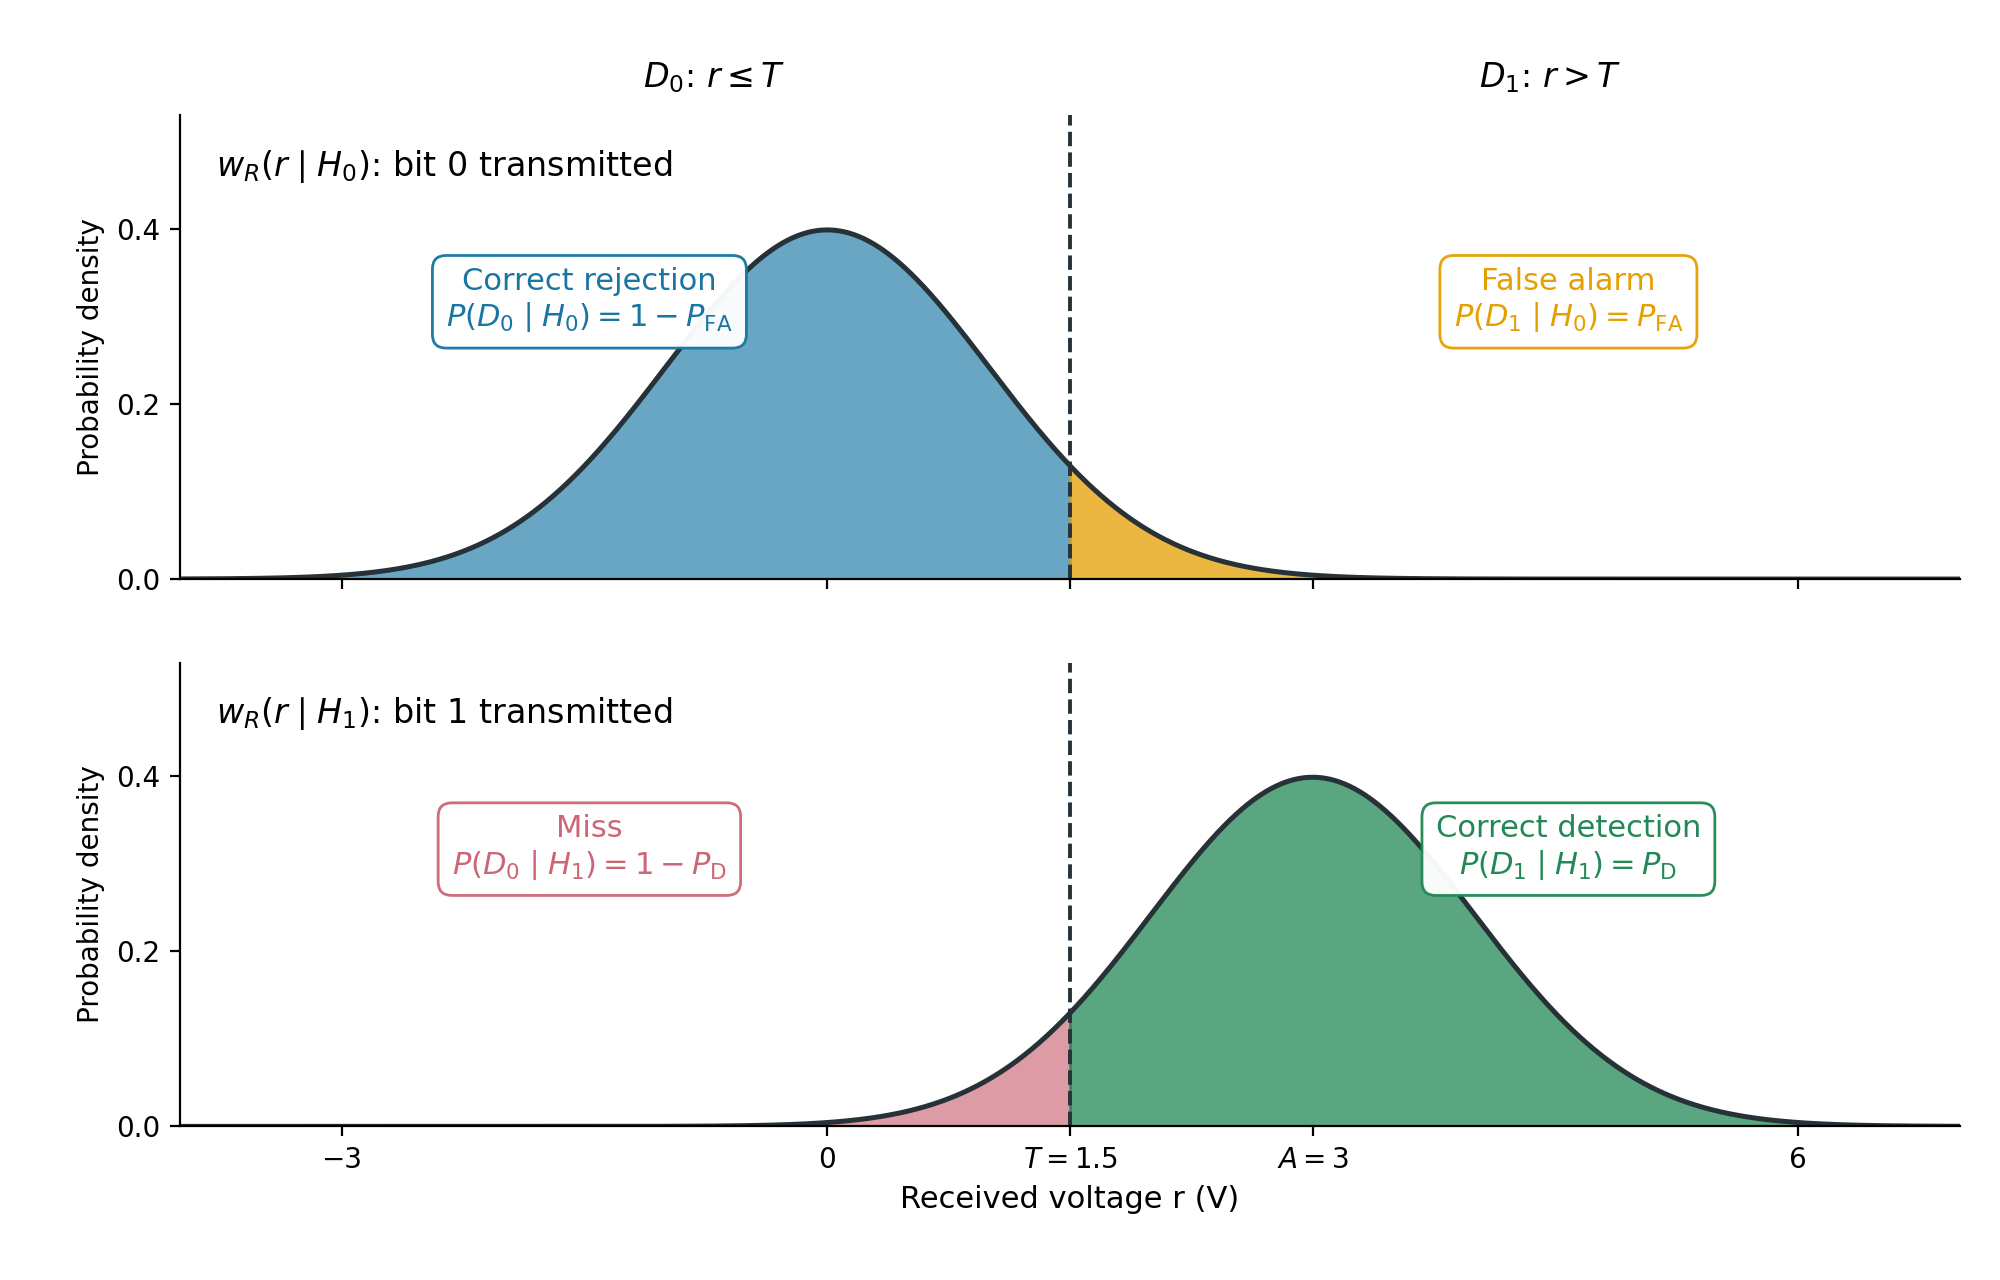
<figcaption>Figure 1: The four conditional probabilities are areas under
the two conditional distributions. The threshold value splits each
density into decisions <span
class="math inline"><em>D</em><sub>0</sub></span> (left) and <span
class="math inline"><em>D</em><sub>1</sub></span> (right). Illustration
for Gaussian noise with standard deviation 1 V and <span
class="math inline"><em>A</em> = 3</span> V.</figcaption>
</figure>

In practice, these values can be estimated from a finite number of
observations, by counting.

<span id="eq-estimated-probabilities">$$
\widehat{P}_{\mathrm{FA}} = \frac{\text{number of false alarms}}{\text{number of transmitted bit 0s}}
\qquad
\widehat{P}_{\mathrm{D}} = \frac{\text{number of correct detections}}{\text{number of transmitted bit 1s}}.
 \qquad(3)$$</span>

## 2.3 Maximum likelihood criterion

How to choose the value of the threshold $T$, i.e. how to take a
decision based on a received voltage $r$?

The **Maximum Likelihood (ML)** criterion chooses the hypothesis with
the larger density function at the received voltage $r$:

- take decision $D_1$ if $w_R(r\mid H_1)>w_R(r\mid H_0)$
- take decision $D_0$ if $w_R(r\mid H_1)\le w_R(r\mid H_0)$.

In our case, this means choosing the threshold $T$ at the intersection
of the two densities, which is in the middle, as shown in
<a href="#fig-conditional-probabilities"
class="quarto-xref">Figure 1</a>.

$$
T_{\mathrm{ML}} = \frac{0 + A}{2}
$$

## 2.4 Changing the threshold: the ROC curve

In general, choosing a threshold $T$ is a tradeoff between false alarms
and correct detections.

The **receiver operating characteristic (ROC)** is a graphical
representation obtained by varying $T$ and plotting:

- horizontal axis: $P_{\mathrm{FA}}$;
- vertical axis: $P_{\mathrm{D}}$.

Each threshold value gives one point. The designer picks the threshold
that meets the requirements.

The ROC curve indicates how well the two hypotheses can be separated
across thresholds.

<figure id="fig-typical-roc">
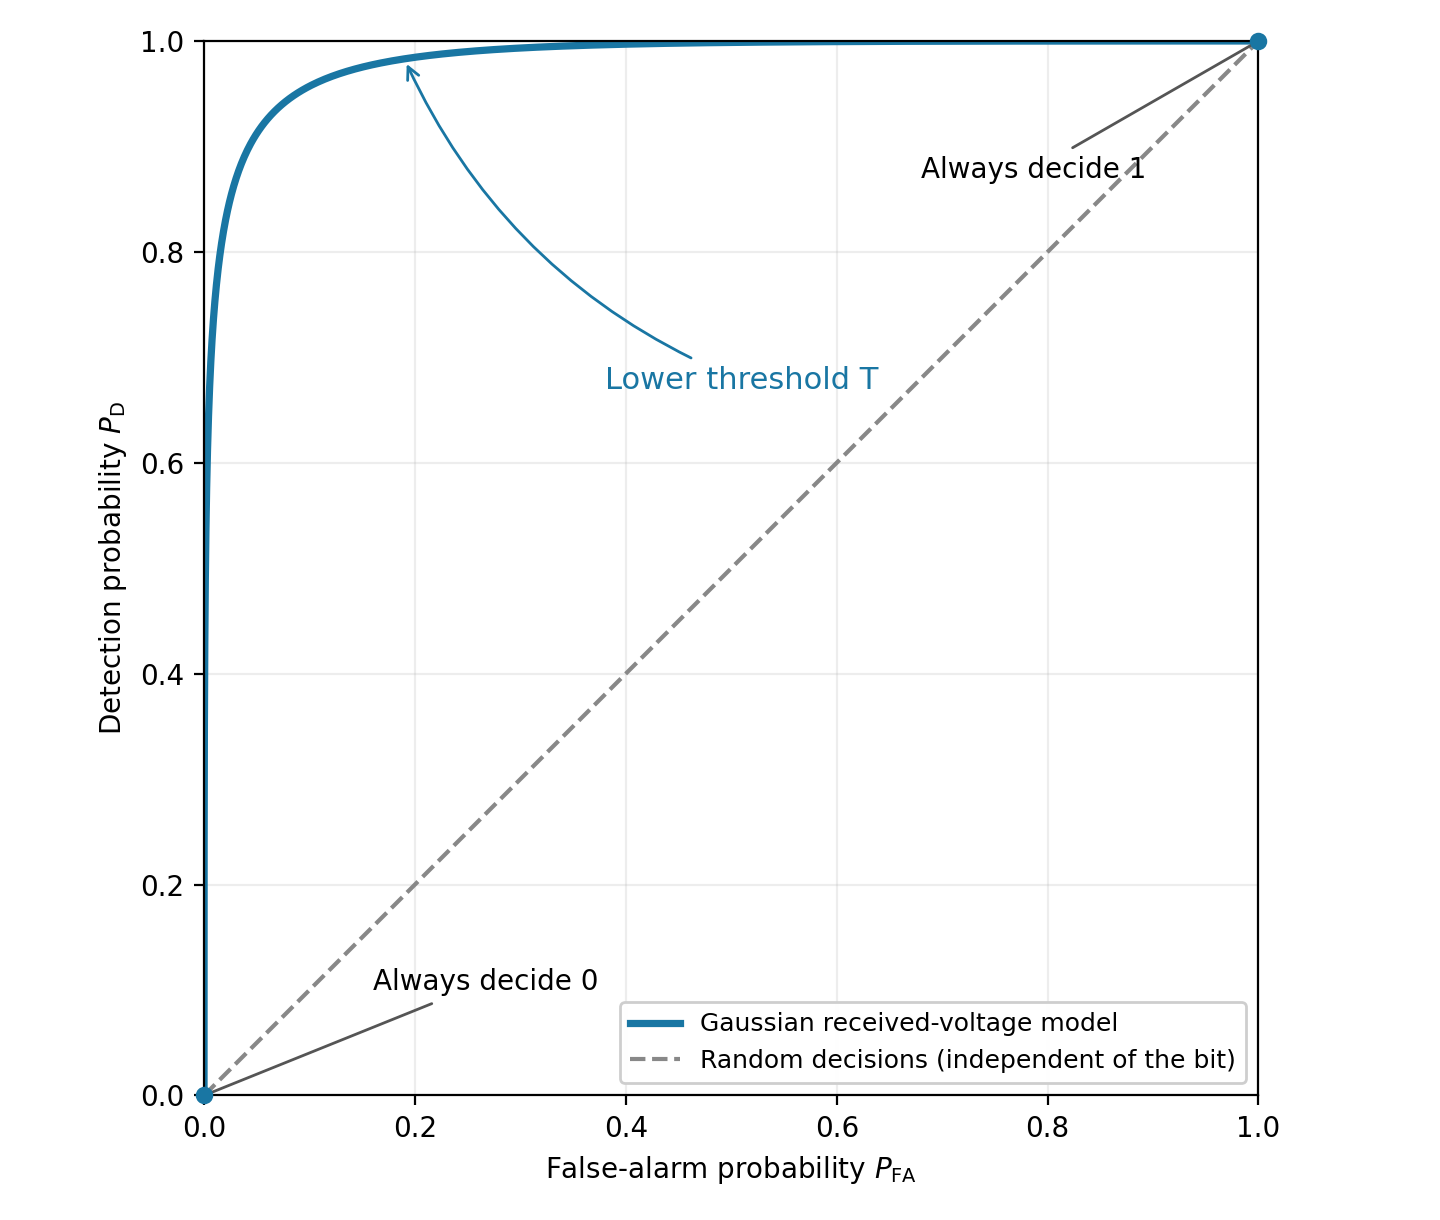
<figcaption>Figure 2: A typical ROC curve for the lab’s Gaussian model
(<span class="math inline"><em>A</em> = 3</span> V, noise standard
deviation 1 V). Lowering the threshold moves the operating point from
<span class="math inline">(0, 0)</span> towards <span
class="math inline">(1, 1)</span>. The dashed diagonal represents random
decisions independent of the transmitted bit; curves closer to the
upper-left corner indicate better separation.</figcaption>
</figure>

## 2.5 Matlab tools

### Generating random bits with chosen probabilities

Use `rand(1,N)` to generate `N` uniform samples between 0 and 1.
Comparing each sample with 0.5 produces random bits with equal
probabilities:

``` matlab
N = 20000;
bits = rand(1,N) > 0.5;
```

To change the proportions, adapt the comparison threshold. For example,
to obtain approximately **30% zeros and 70% ones**:

``` matlab
bits = rand(1,N) > 0.3;
```

Samples at or below 0.3 become 0; samples above 0.3 become 1. Since
`rand()` is uniform, the probabilities are $P(0)=0.3$ and $P(1)=0.7$.

More generally, `rand(1,N) > p0` produces zeros with probability `p0`
and ones with probability `1-p0`.

### Transmitted and received voltages

Multiply the bit vector by $A$, or use similar methods, to obtain the
transmitted voltages.

Use `randn()` as in Lab 3 to generate independent Gaussian noise and add
it to the transmitted voltages to obtain the received vector `r`.

We can separate received samples according to the **transmitted** bits,
not the receiver’s decisions, using logical indexing.

``` matlab
r0 = r(bits == 0);
r1 = r(bits == 1);
```

Reminder: `==` tests equality element by element, while `=` assigns a
value to a variable.

### Varying the threshold for the ROC

To vary the threshold, create a vector such as `thresholds = -4:0.05:7`.
Preallocate result vectors with `zeros(size(thresholds))`, then use a
`for` loop to fill one entry per threshold. Plot the ROC with
`plot(pFA,pD)`.

## 2.6 Summary: functions and notation you should know

| Signature or notation | Example | Description |
|------------------------|------------------------|------------------------|
| `rand(1,N) > p0` | `bits = rand(1,N) > 0.3` | Random bits: probability `p0` of 0 and `1-p0` of 1 |
| `A*bits` | `s = 3*bits` | Map bits to transmitted voltage levels 0 and $A$ |
| `r(bits == 0)` | `r0 = r(bits == 0)` | Select received samples whose transmitted bit was 0 |
| `mu + sigma*randn(1,N)` | `3 + randn(1,10000)` | Normal samples with mean `mu` and standard deviation `sigma` |
| `r > T` | `decision = r > 1.5` | Logical decisions: 1 for $D_1$, 0 for $D_0$ |
| `sum(condition)` | `sum(r0 > T)` | Count observations satisfying a condition |
| `numel(x)` | `numel(r0)` | Number of observations in a vector |
| `hold on`, `hold off`, `legend(...)` | `legend('Bit 0 transmitted','Bit 1 transmitted')` | Overlay plots and identify them |
| `a:step:b` | `-4:0.05:7` | Candidate thresholds with a fixed step |
| `zeros(size(v))` | `pFA = zeros(size(thresholds))` | Preallocate a vector with the same dimensions as `v` |
| `for k = 1:numel(v)` | `T = thresholds(k)` inside the loop | Visit each candidate by index |
| `plot(x,y)` | `plot(pFA,pD)` | Plot detection probability against false-alarm probability |

# 3. Theoretical exercise

A transmitter sends bit 0 as 0 V and bit 1 as 3 V. The received sample
is $r=s+n$, where the noise has the normal distribution
$\mathcal{N}(0,1)$ with voltages expressed in volts. The receiver
decides $D_1$ if $r>T$, and $D_0$ otherwise.

1.  Compute the theoretical probabilities of false alarm and correct
    detection:

    1.  Draw the distribution of $r$ under each hypothesis, $w(r|H_0)$
        and $w(r|H_1)$.

    2.  What is the value of $T$ for the Maximum Likelihood (ML)
        decision rule?

    3.  Compute the false-alarm probability $P_{\mathrm{FA}}$ and the
        detection probability $P_{\mathrm{D}}$ for the ML threshold.

# 4. Matlab exercises

Write your commands in a script or live script. Label figures and record
your numerical results and short explanations in comments. Use the same
generated vectors throughout Exercises 1–3; do not generate new received
samples inside the threshold loop.

1.  Simulate transmission using two voltage levels:

    Use $A=3$ V. The channel adds independent Gaussian noise with mean 0
    V and standard deviation 1 V to each transmitted voltage. Thus,
    received samples follow $\mathcal{N}(0,1)$ under $H_0$ and
    $\mathcal{N}(3,1)$ under $H_1$, with voltages expressed in volts.
    Each sample leads to one bit decision.

    1.  Generate a row vector `bits` of 20000 random bits 0 and 1, with
        equal probabilities. Do this by calling `rand()` and comparing
        with a suitable threshold.

    2.  Transform `bits` to a vector `s` of transmitted voltages, using
        0 V for bit 0 and 3 V for bit 1.

    3.  Generate a noise vector of the same size, with the normal
        distribution $\mathcal{N}(0,1)$, and create a received vector
        `r = s + n`.

    4.  Run the code below to estimate the two conditional densities.
        Can a threshold separate all received samples correctly?

        ``` matlab
        % Select received samples according to the transmitted bit
        r0 = r(bits == 0);  % What does this line do?
        r1 = r(bits == 1);  % What does this line do?

        % Use the same bin boundaries for both histograms
        edges = -4:0.25:7;
        figure
        histogram(r0, edges, 'Normalization', 'pdf', ...
            'FaceColor', [0 0.45 0.74], 'FaceAlpha', 0.5)
        hold on
        histogram(r1, edges, 'Normalization', 'pdf', ...
            'FaceColor', [0.85 0.33 0.10], 'FaceAlpha', 0.5)
        hold off
        xlabel('Received voltage (V)')
        ylabel('Estimated probability density')
        legend('Bit 0 transmitted', 'Bit 1 transmitted')
        ```

    5.  From the histograms, choose an appropriate threshold $T$ to
        separate the two distributions. What happens to false alarms and
        misses when the threshold increases? What about when it
        decreases?

2.  Evaluate individual thresholds:

    1.  Set `T = 1.5`. Compute the vector of decisions `d` by comparing
        the values in `r` with the threshold. Each element of `d` should
        be 1 ($D_1$) if the received voltage is greater than `T`, and 0
        ($D_0$) otherwise. The vectors `bits`, `r`, and `d` must all
        have the same size.

    2.  Compare `d` with the transmitted vector `bits` and count the
        four possible outcomes:

        - false alarms: the transmitted bit is 0, but the decision is 1;
        - correct rejections: the transmitted bit is 0 and the decision
          is 0;
        - correct detections: the transmitted bit is 1 and the decision
          is 1;
        - misses: the transmitted bit is 1, but the decision is 0.

        Use `==` to test equality, `&` to combine two logical conditions
        element by element, and `sum()` to count the positions
        satisfying both conditions. Put parentheses around each
        comparison.

    3.  Count the transmitted 0s and 1s, storing the counts in `N0` and
        `N1`. Verify that false alarms plus correct rejections equal
        `N0`, and correct detections plus misses equal `N1`.

    4.  Estimate the probability of false alarm `pFA` by dividing the
        counts of false alarms by `N0`. Estimate `pD` by dividing the
        correct detection count by `N1`, and the miss probability by
        dividing the miss count by `N1`. Verify that the detection and
        miss probabilities add up to 1.

        For `T = 1.5`, compare `pFA` and `pD` with the theoretical
        results from the [theoretical
        exercise](#sec-theoretical-exercise). Why are the estimates not
        exactly equal to theory?

    5.  Calculate the total number of errors as false alarms plus
        misses. Check it by counting the positions where `d` differs
        from `bits`, using `~=` (not equal).

    6.  Repeat for `T = 1` and `T = 2`, using the same `bits` and `r`.
        Record a small table with one row per threshold and columns for
        `T`, `pFA`, `pD`, and the total error count. Compare with your
        prediction from Exercise 1.

3.  Draw the ROC:

    1.  Create a vector `thresholds` of candidate thresholds from -4 to
        7 in steps of 0.05.

    2.  Complete the template below to calculate `pFA` and `pD` for each
        threshold. Replace each `...` with the appropriate expression,
        using the counting method from Exercise 2. Do not generate new
        noise inside the loop.

        ``` matlab
        pFA = zeros(size(thresholds));
        pD = zeros(size(thresholds));

        for k = 1:numel(thresholds)
            T = thresholds(k);

            % Compute decisions for the received samples
            d = ...;

            % Compare decisions with transmitted bits and count outcomes
            falseAlarms = ...;
            correctDetections = ...;

            % Divide by the number of samples for the corresponding true bit
            pFA(k) = ...;
            pD(k) = ...;
        end
        ```

    3.  Plot the vector `pD` against `pFA`.

# 5. Final questions

1.  If every received voltage increases by 10 V, how should the
    threshold change to keep every decision unchanged? Would the ROC
    change?
2.  Can a detector have no false alarms in 10000 simulated samples for
    transmitted bit 0 even though its true false-alarm probability is
    positive?
3.  A receiver always outputs $D_0$ (bit 0). What are its detection and
    false-alarm probabilities? Where is its point on the ROC? What if it
    always outputs $D_1$ instead?